In [7]:
import meep as mp
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# BƯỚC 1: ĐỌC BẢN QUÉT POLYCAM (FLOOR PLAN)
1. Đọc ảnh và chuyển thành ảnh xám (Grayscale)
2. Cắt bỏ phần dưới của hình (chứa các thông số kỹ thuật) để quét nhầm thành tường
3. Từ bức ảnh sau khi cắt phần dưới --> resize lại với mức độ phân giải (RESOLUTION) mong muốn
4. Từ bức ảnh đã được resized, xoay trục để khớp với lưới tính toán của MEEP
5. Khởi tạo ma trận epsilon (mặc định không khí có epsilon = 1)
6. Gán giá trị epsilon cho các phần tử: cửa kính, tường bê tông (dựa trên độ sáng phần tử trên ma trận)

In [ ]:
# Kích thước thực tế của trường quét bằng LiDAR
SX, SY = 15.0, 12.0
RESOLUTION = 15 # Độ phân giải FDTD (15 pixels / 1 met thực tế)
cell = mp.Vector3(SX,SY,0)

def create_school_map_from_polycam(image_path,sx, sy, res):
    """
    Khi có ảnh Floorplan xuất từ Polycam, đọc ảnh và chuyển thành ma trận chiết suất.
    """
    # 1. Đọc ảnh mặt bằng của Polycam ('L': Chuyển về ảnh xám Grayscale)
    # Dựa vào độ sáng để xác định tường học không gian phòng.
    img = Image.open(image_path).convert('L')
    width, height = img.size
    
    # 2. Cắt bỏ 12% chiều cao của hình (tránh đọc nhầm dòng chữ ở dưới)
    img_cropped = img.crop((0,0,width,int(height*0.88)))
    
    # 3. Resize lại khung hình để khớp với lưới tính toán của MEEP
    grid_width, grid_height = int(sx * res), int(sy * res) # Độ phân giải bản đồ vật liệu
    img_resized = img_cropped.resize((grid_width, grid_height))
    
    # 4. Xoay trục ảnh vừa được resized để khớp với trục (X,Y) của MEEP
    img_arr = np.flipud(np.array(img_resized)).T
    
    # 5. Khởi tạo ma trận: Mặc định toàn bộ là không khí (epsilon = 1.0)
    eps_map = np.ones((grid_width, grid_height), dtype=np.float32)
    
    
    # Pixel sáng (~255) là nền trắng / không gian trống
    # Pixel vừa (<180) là cửa gỗ/kính (eps = 2.5)
    # Pixel tối (<80) là tường bê tông (eps = 6.25)
    eps_map[img_arr < 180] = 2.5   # Cửa kính / Vách gỗ
    eps_map[img_arr < 80] = 6.25   # Tường bê tông cốt thép (n = 2.5 -> eps = n^2 = 6.25)
        
    return eps_map

# Xác định ma trận trích suất từ ảnh của Polycam
img_path = "/home/dungduchp2945/KHKT_2026_Wifi_RL/data/raw/phong_ngu_test.jpg"
eps_matrix = create_school_map_from_polycam(img_path, SX, SY, RESOLUTION) # khi nào có ảnh thật thì thay bằng img_path

# BƯỚC 2: HÀM TRUY XUẤT VẬT LIỆU TỰ ĐỘNG CHO MEEP #
Hàm "polycam_material_func(p)" thực hiện biến đổi tuyến tính để dổi tọa độ theo mét $(x,y)$ sang chỉ số hàng cột $(ix, iy)$ của ma trận eps_matrix (theo pixel):
$$ix = \text{int}\left( \frac{x + \frac{SX}{2}}{SX} \times \text{Width}_{\text{matrix}} \right), \quad iy = \text{int}\left( \frac{y + \frac{SY}{2}}{SY} \times \text{Height}_{\text{matrix}} \right)$$

In [ ]:
def polycam_material_func(p):
    # Chuyển tọa độ mét của MEEP (-SX/2 -> SX/2) sang index của ma trận
    ix = int(np.clip((p.x + SX / 2) / SX * eps_matrix.shape[0], 0, eps_matrix.shape[0] - 1))
    iy = int(np.clip((p.y + SY / 2) / SY * eps_matrix.shape[1], 0, eps_matrix.shape[1] - 1))
    
    return mp.Medium(epsilon=eps_matrix[ix, iy])

# BƯỚC 3: CHẠY MÔ PHỎNG LẮP ĐẶT ROUTER VÀ TINH CHỈNH HỆ THỐNG LẮP ĐẶT
1. CƠ CHẾ LẮP ĐẶT AP: 
- ap_positions[] bao gồm các bộ ba giá trị $(x,y,amp)$ với $(x,y)$ là tọa độ AP, còn $amp$ đại diện cho công suất phát của AP đó (tùy theo Tier) 
- Theo từng bước lập: đặt đối tượng nguồn phát ($mp.Source$) tại vị trí (x,y,0)

2. TẠO NGUỒN PHÁT VÀ THỰC HIỆN GIẢ LẬP PHÁT:
-  Tạo nguồn phát sóng điện từ liên tục ở tần số đại diện $2.4\text{ GHz}$ với trường điện phân cực dọc theo trục $Z$ ($E_z$).
-  Tạo lớp biên hấp thụ hoàn hảo dày $1.0\text{ m}$ bao quanh bản đồ để sóng bay ra rìa không bị phản xạ ngược vào trong phòng.
-  Gắn bản đồ vật liệu thực tế từ ảnh quét LiDAR Polycam vào lưới FDTD.   
-  Cho sóng điện từ lan truyền, đập tường, phản xạ và xuyên thấu trong 120 đơn vị thời gian MEEP (tương đương 1440 bước thời gian ở resolution=6)

3. CÁC KẾT QUẢ TRẢ VỀ:
- $dielectric$: Ma trận hằng số điện môi $\varepsilon(x,y)$ của toàn bộ mặt bằng ($\varepsilon=1.0$ là không khí, $2.5$ là cửa kính/gỗ, $6.25$ là tường bê tông), dùng để vẽ khung kiến trúc nền.   
- $E_z-energy$: Đại lượng $\vert{}E_z\vert{}^2$, tỷ lệ thuận trực tiếp với mật độ công suất sóng điện từ trung bình $\langle S \rangle = \frac{E_0^2}{2\eta_0}$ tại mỗi điểm ảnh.
- $RSSI = 10\log_{10}(\vert{}E_z\vert{}^2 + 10^{-6})$: Quy đổi năng lượng sóng sang thang đo logarit (Decibel) theo công thức để làm nổi bật các Vùng chết tín hiệu (Dead Zones) trên biểu đồ nhiệt

In [ ]:
def simulate_topology(ap_positions, title):
    sources = [
        mp.Source(
            mp.ContinuousSource(frequency=2.4),
            component=mp.Ez,
            center=mp.Vector3(x, y, 0),
            amplitude=amp # Đại diện cho công suất phát Tx Power (Tier-1/2/3)
        ) for (x, y, amp) in ap_positions # Thông tin AP: vị trí (x,y) và amp (công suất phát)
    ]
    
    sim = mp.Simulation(
        cell_size=cell,
        boundary_layers=[mp.PML(1.0)], # Biên hấp thụ quanh bản đồ để sóng không phản xạ lại 
        default_material=polycam_material_func,
        sources=sources,
        resolution=6 # Giữ resolution vừa phải (6-10) để chạy nhanh trên laptop
    )
    sim.run(until=120)
    
    # Trích xuất dữ liệu
    dielectric = sim.get_array(center=mp.Vector3(), size=cell, component=mp.Dielectric)
    ez_energy = np.abs(sim.get_array(center=mp.Vector3(), size=cell, component=mp.Ez))**2
    
    # Quy đổi tương đối sang thang đo dB để nhìn rõ Vùng Chết (Dead Zones)
    rssi_db = 10 * np.log10(ez_energy + 1e-6)
    return dielectric, rssi_db

legacy_aps = [(-8, -6, 1.5), (8, -6, 1.5)] 

# Kịch bản M (Đề xuất KHKT 2026): 
# Đưa AP Tier-2 vào trực tiếp tâm lớp học (LOS), 
# đặt 1 AP Tier-3 công suất nhỏ ở hành lang
optimized_aps = [(-10, 3, 1.0), (0, 3, 1.0), (10, 3, 1.0), (0, -6, 0.4)]

# BƯỚC 4: TRỰC QUAN HÓA BIỂU ĐỒ NHIỆT

-----------
Initializing structure...
time for choose_chunkdivision = 0.00274014 s
Working in 2D dimensions.
Computational cell is 15 x 12 x 0 with resolution 6
time for set_epsilon = 1.57068 s
-----------
run 0 finished at t = 120.0 (1440 timesteps)
-----------
Initializing structure...
time for choose_chunkdivision = 0.00011301 s
Working in 2D dimensions.
Computational cell is 15 x 12 x 0 with resolution 6
time for set_epsilon = 1.45197 s
-----------
run 0 finished at t = 120.0 (1440 timesteps)


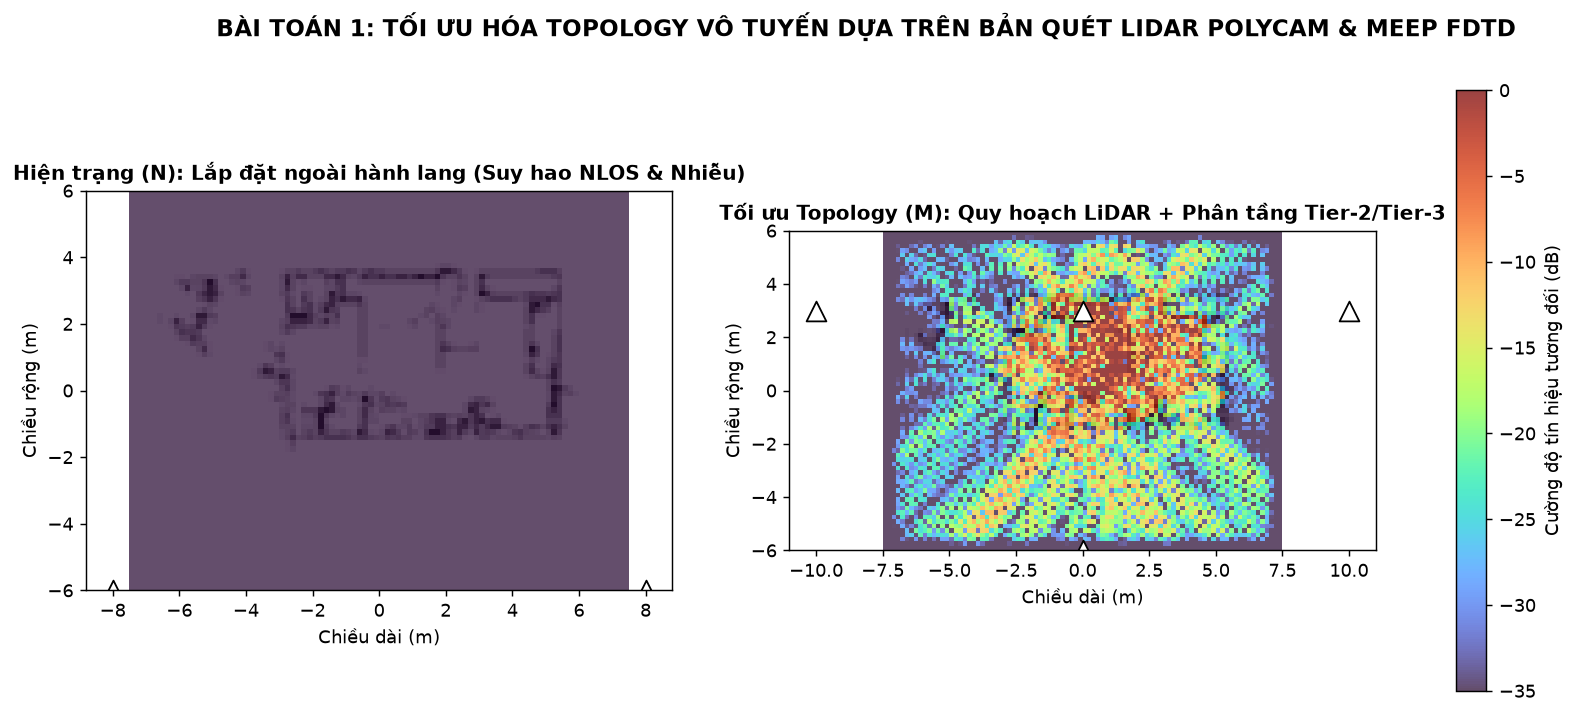

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=130)

for ax, aps, label in zip(axes, [legacy_aps, optimized_aps], 
                          ["Hiện trạng (N): Lắp đặt ngoài hành lang (Suy hao NLOS & Nhiễu)", 
                           "Tối ưu Topology (M): Quy hoạch LiDAR + Phân tầng Tier-2/Tier-3"]):
    diel, rssi = simulate_topology(aps, label)
    
    # Vẽ khung tường Polycam
    ax.imshow(diel.T, cmap='binary', origin='lower', extent=[-SX/2, SX/2, -SY/2, SY/2])
    # Phủ Heatmap cường độ sóng
    im = ax.imshow(rssi.T, cmap='turbo', alpha=0.75, vmin=-35, vmax=0, origin='lower', extent=[-SX/2, SX/2, -SY/2, SY/2])
    
    # Đánh dấu vị trí lắp đặt Router
    for (x, y, _) in aps:
        ax.scatter(x, y, c='white', edgecolors='black', s=120, marker='^', label='Vị trí AP')
        
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel("Chiều dài (m)")
    ax.set_ylabel("Chiều rộng (m)")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Cường độ tín hiệu tương đối (dB)")
plt.suptitle("BÀI TOÁN 1: TỐI ƯU HÓA TOPOLOGY VÔ TUYẾN DỰA TRÊN BẢN QUÉT LIDAR POLYCAM & MEEP FDTD", 
             fontsize=13, fontweight='bold')
plt.show()